In [28]:
import uproot
import awkward as ak 
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

paths_water = [    
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-band-blocker-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-band-blocker-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-no-mask-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-mask-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-water-beta-mask-500nm-lp-centered_lappd_1.root", ]


paths_lab = [
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-no-mask-band-blocker-500nm-lp-centered-redo_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-mask-band-blocker-500nm-lp-centered_lappd_0.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-mask-band-blocker-500nm-lp-centered_lappd_1.root",
    "C:\\Users\\Evan\\Downloads\\lappd-158-lab1.7ppo-beta-no-mask-band-blocker-500nm-lp-centered-redo_lappd_0.root",]
    

n_tup = uproot.open(paths_lab[0])
output = n_tup["output;1"]
event_info = output.arrays(output.keys(), library="ak")
lcns = event_info['lcns']
waveforms = event_info['waveforms']
adc_to_V = 2 / (2**14)
above_ped = 5
consecutive = 3
times = []


def res_perfile(filepath):
    n_tup = uproot.open(filepath)
    output = n_tup["output;1"]
    event_info = output.arrays(output.keys(), library="ak")
    waveforms = event_info['waveforms']
    above_ped = 5
    consecutive = 3
    
    for i in range(len(waveforms)):
        tr_times = []
        for k in range(len(waveforms[0]) - 1, -1, -1):
        
         if 30 < k < 35 :
            
            wf = waveforms[i][k][100:-100]
            ped = ak.mean(wf[0:400])
            peak = ak.max(wf)
            amp = peak - ped
            crossed = wf > 0.6 * (amp) + ped
            above = ak.where(crossed)[0]
            tr_times.append((above[0] + 100) * 0.2)
            
                
         if k < 30:
            first_bins= []
            wf = waveforms[i][k][10:-10]
            ped = ak.mean(wf[500:900])
            cut = ped + above_ped
            
            crossed = wf > cut 
            above = ak.where(crossed)[0]
            
            if len(above) >= consecutive:
                diffs = above[1:] - above[:-1]

        # places where the run breaks
                breaks = ak.where(diffs > 1)[0]

        # start indices of each run
                starts = ak.concatenate([[0], breaks + 1])
                ends   = ak.concatenate([breaks + 1, [len(above)]])

                lengths = ends - starts

        # select only runs long enough
                good = starts[lengths >= consecutive]

                first_bins = above[good] + 10
                
            else:
             first_bins = []

        
        if len(first_bins) == 1:
            if  k < 8 :
                times.append(first_bins[0] * 0.2 - tr_times[3])
                
            if (7 < k < 16) :
                times.append(first_bins[0] * 0.2 - tr_times[2])
            if (15 < k < 24) :
                times.append(first_bins[0] * 0.2 - tr_times[1])
            if (23 < k < 31) :
                times.append(first_bins[0] * 0.2 - tr_times[0])
        


res_perfile(paths_water[0])
res_perfile(paths_water[1])
res_perfile(paths_water[2])
res_perfile(paths_water[3])
res_perfile(paths_water[4])
res_perfile(paths_water[5])

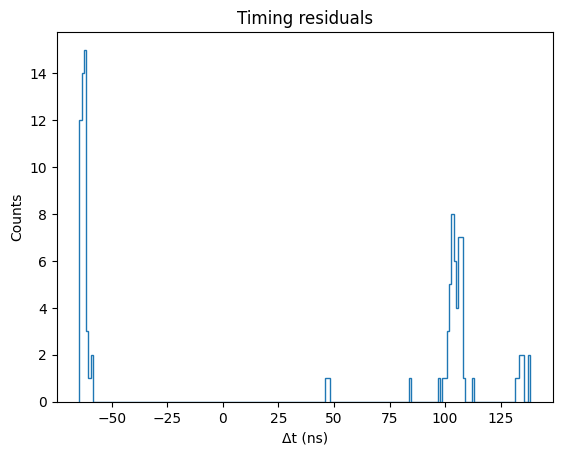

In [31]:

plt.hist(times, bins=200, histtype="step")
plt.xlabel("Δt (ns)")
plt.ylabel("Counts")
plt.title("Timing residuals")
plt.show()